# Geometry to sound: how `didgelab.synth` plays a bore

`didgelab.synth` turns a bore geometry, a list of points `[[x_mm, d_mm], ...]`, into the sound of a played
didgeridoo. This notebook explains

1. **Introduction**: the idea of the synthesizer, without physics
2. **Maths**: bore, lips, vocal tract, coupling and rendering in formulas
3. **Code examples**: every step computed and plotted, two short sound examples

The full article with the calibration on the Didge Archive is [synthesizer.md](../synthesizer.md). The
song language is described in [song_format.md](../song_format.md).

## 1. Introduction

A played didgeridoo has three parts that work together:

* **The didgeridoo (the bore).** It has resonances: frequencies at which the air column in the tube
  rings easily. DidgeLab computes them from the shape. The lowest one is the drone, the higher ones are the
  toots. The bore also decides how much of each frequency comes out of the bell. A frequency that falls on a
  resonance comes out strongly, a frequency between two resonances is weak.
* **The lips.** The lips open and close once per period of the drone. They let short puffs of air into the
  didgeridoo. Because the lips close completely for part of each cycle, the puffs are rich in overtones
  (harmonics: 2, 3, 4, … times the drone frequency).
* **The mouth and throat (the vocal tract).** The air in the player's mouth is a second, small resonator,
  behind the lips. Where the mouth resonates strongly, little air can pass the lips at that frequency.
  Between those frequencies the sound is bright. These bright bands are the **formants**, and moving the
  tongue moves them. This is the "wah", "ee"–"oo" or tongue front/back technique.

The synthesizer computes how much of each harmonic of the lips reaches the bell, given the bore and the
mouth shape. Then it adds all harmonics together. A **score** (for example `doo:2 di:.5 ga:.5 *too`)
says how the player moves the tongue, the lips and the breath over time. From that the synthesizer
renders audio.

What the synthesizer does *not* do: the lips do not find the playing frequency themselves. The drone is
played exactly on the first resonance and a toot 34 cents below a higher resonance, as measured in the
recordings of the Didge Archive.

What you can use it for: listen to a bore before you build it, compare two designs by ear, hear what a
wider bell or a longer tube changes.

## 2. Maths

This is a condensed version of sections 1–5 of [synthesizer.md](../synthesizer.md). The symbols match
the code in `src/didgelab/synth/`.

### 2.1 The bore: transmission-line model (`bore.py`)

The bore is a chain of truncated cones between the points $(x_i, d_i)$. For each segment, a $2\times 2$
transfer matrix maps pressure $p$ and volume flow $U$ at its output to its input:

$$\begin{pmatrix}p_{in}\\U_{in}\end{pmatrix} = \mathbf T_i(\omega)\begin{pmatrix}p_{out}\\U_{out}\end{pmatrix}.$$

For a cone with slant length $l$, distances $x_0, x_1$ of its ends from the cone apex, propagation constant
$\Gamma$ and characteristic impedance $Z_c$:

$$\mathbf T = \begin{pmatrix}
\dfrac{x_1}{x_0}\Big(\cosh\Gamma l - \dfrac{\sinh\Gamma l}{\Gamma x_1}\Big) &
\dfrac{x_0}{x_1} Z_c \sinh \Gamma l \\[2ex]
\dfrac{1}{Z_c}\Big[\Big(\dfrac{x_1}{x_0}-\dfrac{1}{\Gamma^2x_0^2}\Big)\sinh\Gamma l
 + \dfrac{\Gamma l}{(\Gamma x_0)^2}\cosh\Gamma l\Big] &
\dfrac{x_0}{x_1}\Big(\cosh\Gamma l + \dfrac{\sinh\Gamma l}{\Gamma x_0}\Big)
\end{pmatrix},$$

and for a cylinder of length $L$

$$\mathbf T = \begin{pmatrix}\cosh\Gamma L & Z_c\sinh\Gamma L\\ \sinh\Gamma L / Z_c & \cosh\Gamma L\end{pmatrix}.$$

Losses at the wall enter through $r_v = \sqrt{\rho\,\omega\,\bar A/(\pi\eta)}$ ($\bar A$: area at the mean
diameter of the segment, $\eta$: viscosity of air):

$$\Gamma = \frac{\omega}{c}\left[\frac{1.045}{r_v} + j\left(1+\frac{1.045}{r_v}\right)\right],
\qquad
Z_c = \frac{\rho c}{A_0}\left[1+\frac{0.369}{r_v} - j\frac{0.369}{r_v}\right],$$

with $A_0$ the area at the segment input. The whole bore is the product
$\mathbf M = \prod_i \mathbf T_i = \begin{pmatrix}A&B\\C&D\end{pmatrix}$. At the bell it is terminated by
the radiation impedance of an unflanged pipe (Levine & Schwinger, low $ka$),
$Z_r = \frac{\rho c}{S}\,[(\omega d/c)^2/16 + j\,0.3\,\omega d/c]$, with $d$ the diameter and $S$ the area
of the bell opening. The imaginary part is the end correction: the bore acts as if it were $0.6\,d/2$ longer.

The **input impedance** (what DidgeLab returns as $|Z_{in}|$) and the **flow transfer function** to the bell
follow from $p_N = Z_r U_N$:

$$Z_{in} = \frac{p_0}{U_0} = \frac{A Z_r + B}{C Z_r + D},
\qquad
U_0 = (C Z_r + D)\,U_N
\;\Rightarrow\;
H(\omega) = \frac{U_N}{U_0} = \frac{1}{C Z_r + D}.$$

Both share the denominator $C Z_r + D$, so both have their peaks at the resonances. `Bore` evaluates these
formulas on a 0.5 Hz grid up to 12 kHz and keeps the complex values.

### 2.2 The lips (`excitation.py`)

The lips are closed for a fraction $1-\text{OQ}$ of every period (OQ: open quotient). In the open phase the
flow is a Rosenberg-type pulse. With the skew $s$ (fraction of the open phase spent opening),
$T_p = s\,\text{OQ}$, $T_n = (1-s)\,\text{OQ}$ and the phase $\tau\in[0,1)$:

$$u(\tau) = \begin{cases}
\tfrac12\big(1-\cos(\pi\tau/T_p)\big) & 0 \le \tau < T_p\\
\cos\big(\tfrac{\pi}{2}(\tau - T_p)/T_n\big) & T_p \le \tau < T_p + T_n\\
0 & \text{otherwise.}
\end{cases}$$

The slope jumps when the lips close, so the harmonic amplitudes fall as $|S_n| \sim n^{-2}$
(−12 dB/octave). The coefficients $S_n(\text{OQ}, s)$ are normalised to unit AC power, so OQ and $s$ change
the timbre, not the loudness. Defaults: $\text{OQ}=0.45$, $s=0.85$.

The lips are a valve with an internal (source) impedance $Z_s$: the AC flow is $U = U_s - \Delta p / Z_s$,
where $U_s$ is the flow into a short circuit and $\Delta p$ the pressure difference across the lips. Default
$Z_s = 0.1$ MPa s/m³.

### 2.3 The vocal tract (`vocaltract.py`)

The tract from the lips to the glottis (16.5 cm) is a chain of $N = 24$ cylinders with areas $A_k$ given by
four parameters: tongue position, tongue height, mouth (jaw) opening and glottis opening. Each cylinder of
length $\Delta$ has the matrix

$$\begin{pmatrix}\cosh\gamma\Delta & Z_k\sinh\gamma\Delta\\ \sinh\gamma\Delta/Z_k & \cosh\gamma\Delta\end{pmatrix},
\qquad Z_k = \frac{\rho c}{A_k},
\qquad \gamma = \frac{\pi\big(B_0 + B_1\sqrt{f/1\,\text{kHz}}\big)}{c} + j\frac{\omega}{c},$$

with $B_0 = B_1 = 30$ Hz (formant bandwidths). The chain continues with the glottis (a 1 cm orifice) and the
trachea (12 cm, 2.5 cm²), which ends in the lungs without reflection ($Z_t = \rho c / A_{tr}$). Seen from
the lips:

$$Z_{vt} = \frac{a Z_t + b}{c Z_t + d}, \qquad
\begin{pmatrix}a&b\\c&d\end{pmatrix} = \prod_{k=1}^{N}\mathbf T_k\;\mathbf T_{\text{glottis}}\;\mathbf T_{\text{trachea}}.$$

### 2.4 Coupling lips, vocal tract and bore (`model.py`)

The same flow $U$ passes vocal tract, lips and bore. The mouth pressure is $-Z_{vt}U$, the mouthpiece
pressure $Z_{in}U$, so $\Delta p = -(Z_{vt}+Z_{in})U$ and the valve equation gives

$$U(f) = U_s(f)\,\frac{Z_s}{Z_s + Z_{vt}(f) + Z_{in}(f)}.$$

The flow at the bell is $H U$, and the bell radiates like a small source, $p \propto j\omega\, U_{bell}$.
Harmonic $n$ of the radiated sound has the complex amplitude

$$P_n = a\, S_n(\text{OQ}, s)\, G(n f_0),
\qquad
G(f) = j\frac{f}{100\ \text{Hz}}\; H(f)\;\frac{Z_s}{Z_s + Z_{vt}(f) + Z_{in}(f)}\;
\Big(\frac{f}{1\ \text{kHz}}\Big)^{\kappa/(20\log_{10}2)},$$

where $a$ is the lip amplitude and the last factor is a tilt of $\kappa = 1$ dB/octave (directivity of bell
and microphone). In the code this is `filter_gain` ($G$) and `harmonic_spectrum` ($S_n G(nf_0)$).

Where $|Z_{vt}|$ is large, the flow is choked and the spectrum has a dip. The bands between these dips are
the formants that the tongue moves.

### 2.5 Rendering (`synth.py`, `techniques.py`)

A score is turned into control signals at 500 Hz: lip frequency $f_0(t)$, lip amplitude $a(t)$, OQ, skew,
the four vocal-tract parameters, noise levels and voice. The drone is played on the first resonance, a
toot (`*too`) 34 cents below the second resonance (`**too`: third). The sound is a bank of harmonics up to
12 kHz (plus breath noise; an optional broadband noise for the highs is off by default, see the article §5.5):

$$y(t) = \sum_{n=1}^{N} \mathrm{Re}\Big\lbrace A_n(t)\,e^{\,jn\theta(t)}\Big\rbrace,
\qquad \theta(t) = 2\pi\!\int_0^t f_0(t')\,dt',
\qquad A_n(t) = a(t)\,S_n(t)\,G\big(nf_0(t); \mathbf v(t)\big).$$

The bore stores energy, so a partial cannot change instantly. Each $A_n$ is smoothed by a one-pole filter
whose time constant is the group delay of the bore,

$$\tau(f) = -\frac{d\arg H(\omega)}{d\omega}\Big|_{\omega=2\pi f}\quad(\text{clipped to }2\ldots300\text{ ms}),
\qquad
A_n[k] \leftarrow e^{-\Delta t/\tau_n}A_n[k-1] + \big(1-e^{-\Delta t/\tau_n}\big)A_n[k].$$

At a resonance $\tau = 1/(\pi B) = Q/(\pi f)$ ($B$: bandwidth), about 0.1 s for a drone. Breath and
frication noise are filtered with $|G|$, and a short room reverb is added.

## 3. Code examples

In [1]:
import sys, time
sys.path.insert(0, "../../src")   # use the didgelab of this repository

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram
from IPython.display import Audio, display

from didgelab import compute_moist_air_properties
from didgelab.synth import (Bore, ModelParams, VOWELS, filter_gain, harmonic_spectrum, synthesize,
                            render_song_loop, SONGS, Synthesizer)
from didgelab.synth import vocaltract
from didgelab.synth.excitation import lips_waveform, hindle_waveform, source_harmonics

constants = compute_moist_air_properties(temp_celsius=28)
params = ModelParams()          # calibrated defaults: OQ 0.45, skew 0.85, Z_s 0.1 MPa s/m³
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 1.5,
                     "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                          "#e87ba4", "#008300", "#6250d6", "#e34948"])})
db = lambda x: 20 * np.log10(np.abs(x) + 1e-30)

def plot_bore(ax, geo, label=None, **kw):
    g = np.array(geo, dtype=float)
    line, = ax.plot(g[:, 0], g[:, 1] / 2, label=label, **kw)
    kw["color"] = line.get_color()
    ax.plot(g[:, 0], -g[:, 1] / 2, **kw)
    ax.set(xlabel="position (mm)", ylabel="radius (mm)")

### 3.1 A bore, its impedance and its transfer function

The bore below is a typical didgeridoo shape (1.45 m, 32 mm mouthpiece, 75 mm bell). `Bore` computes the
complex $Z_{in}$ and $H$. Its $|Z_{in}|$ is the same as DidgeLab's own simulation, which we check first.

In [2]:
geo = [[0, 32], [400, 31], [800, 34], [1050, 40], [1250, 52], [1450, 75]]
bore = Bore(geo, constants=constants)

k = np.where((bore.freqs >= 30) & (bore.freqs <= 3000))[0][::7]     # points of the 0.5 Hz grid
z_ref = np.asarray(bore.didgelab_impedance(bore.freqs[k])).ravel()
print(f"max relative difference of |Z_in| to DidgeLab: {np.max(np.abs(np.abs(bore.Zin[k]) / z_ref - 1)):.1e}")

print("\nresonance   freq (Hz)   |Z| (MPa s/m³)    Q")
for k, r in enumerate(bore.resonances[:6]):
    name = "drone" if k == 0 else f"toot {k}"
    print(f"{name:9s} {r.freq:10.1f} {r.impedance / 1e6:12.2f} {r.q:9.1f}")

max relative difference of |Z_in| to DidgeLab: 1.1e-14

resonance   freq (Hz)   |Z| (MPa s/m³)    Q
drone           75.2        29.35      30.1
toot 1         194.3        13.99      55.5
toot 2         306.6         9.25      76.6
toot 3         422.8         6.98      76.9
toot 4         538.1         5.96      76.9
toot 5         656.3         4.38      72.9


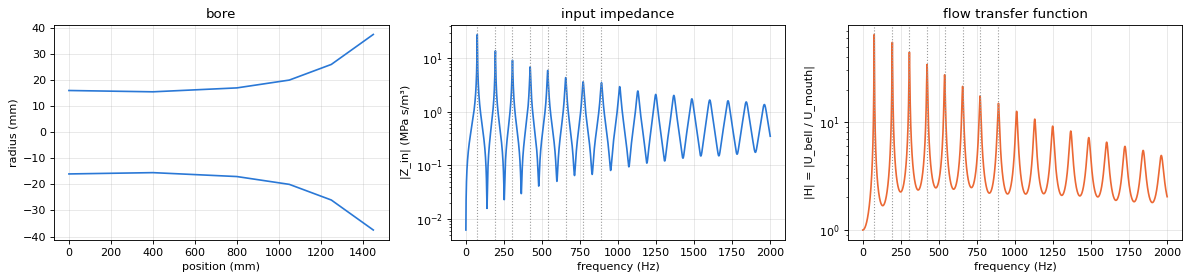

In [3]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 3.6))
plot_bore(a1, geo); a1.set_title("bore")
m = bore.freqs <= 2000
a2.plot(bore.freqs[m], np.abs(bore.Zin[m]) / 1e6)
a2.set(xlabel="frequency (Hz)", ylabel="|Z_in| (MPa s/m³)", yscale="log", title="input impedance")
a3.plot(bore.freqs[m], np.abs(bore.H[m]), color="C1")
a3.set(xlabel="frequency (Hz)", ylabel="|H| = |U_bell / U_mouth|", yscale="log", title="flow transfer function")
for a in (a2, a3):
    for r in bore.resonances[:8]:
        a.axvline(r.freq, color="0.6", ls=":", lw=1)
plt.tight_layout(); plt.show()

Both curves have their peaks at the same frequencies (dotted lines): the resonances. Between the resonances
$|H|$ is small: a harmonic that falls there hardly reaches the bell.

### 3.2 The lip source

One period of the beating-lip flow (OQ 0.45 and a brighter OQ 0.3, skew 0.85; the default is OQ 0.12) and, for comparison,
the smooth Fletcher / Hindle & Posnett source used in Didge2Wav. Right: the harmonic levels $|S_n|$. The
beating lips follow $n^{-2}$ (−12 dB/octave); the smooth source falls off exponentially and is far too dull.

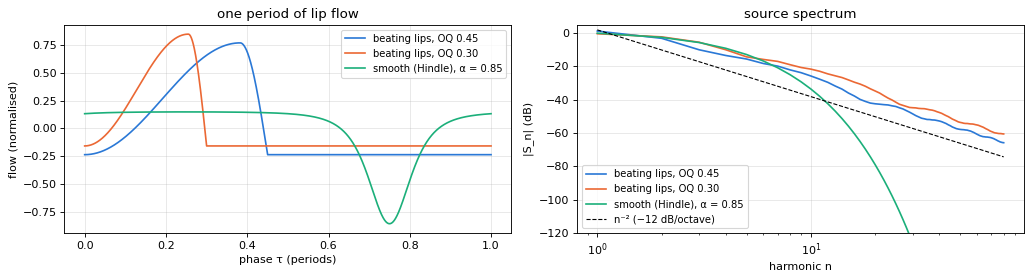

In [4]:
tau = np.arange(4096) / 4096
n = np.arange(1, 81)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6))
for oq, skew, label in [(0.45, 0.85, "beating lips, OQ 0.45"), (0.30, 0.85, "beating lips, OQ 0.30")]:
    u = lips_waveform(oq, skew)
    a1.plot(tau, u / np.ptp(u), label=label)
    a2.plot(n, db(source_harmonics(80, oq=oq, skew=skew)), label=label)
u = hindle_waveform(0.85)
a1.plot(tau, u / np.ptp(u), label="smooth (Hindle), α = 0.85")
a2.plot(n, db(source_harmonics(80, model="hindle", alpha=0.85)), label="smooth (Hindle), α = 0.85")
a2.plot(n, db(source_harmonics(80)[0]) - 40 * np.log10(n), "k--", lw=1, label="n⁻² (−12 dB/octave)")
a1.set(xlabel="phase τ (periods)", ylabel="flow (normalised)", title="one period of lip flow"); a1.legend(fontsize=9)
a2.set(xscale="log", ylim=(-120, 5), xlabel="harmonic n", ylabel="|S_n| (dB)", title="source spectrum"); a2.legend(fontsize=9)
plt.tight_layout(); plt.show()

### 3.3 The vocal tract and the filter gain

Left: $|Z_{vt}|$ for the mouth shapes "ee" (tongue front, `VOWELS["i"]`) and "oo" (tongue back,
`VOWELS["u"]`), together with $|Z_{in}|$ of the bore and the lip source impedance $Z_s$. Right: the filter
gain $|G(f)|$ of §2.4 for both mouth shapes; dots are the harmonics of the drone. Where $|Z_{vt}|$ has a
peak, $|G|$ has a dip. The bright band between the dips (the formant) is higher for "ee" than for "oo".

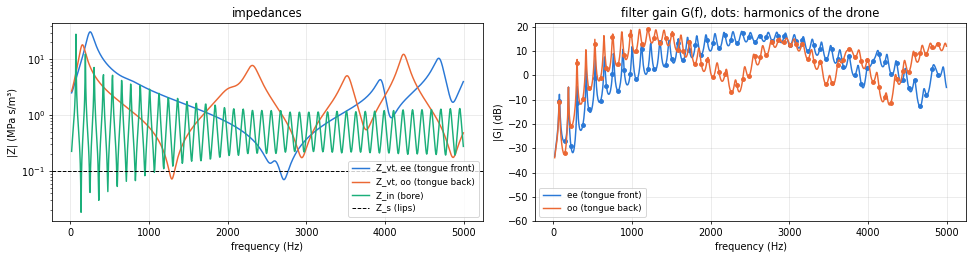

ee (tongue front) : formant at about 2740 Hz
oo (tongue back)  : formant at about 1310 Hz


In [5]:
f = np.arange(20, 5000, 5.0)
f0 = bore.drone
nh = np.arange(1, int(5000 / f0))
shapes = {"ee (tongue front)": VOWELS["i"], "oo (tongue back)": VOWELS["u"]}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8), dpi=70)
for k, (label, vt) in enumerate(shapes.items()):
    a1.plot(f, np.abs(vocaltract.impedance(vt, f)) / 1e6, label=f"Z_vt, {label}", color=f"C{k}")
    g = filter_gain(bore, f, vt, params)
    a2.plot(f, db(g), color=f"C{k}", label=label)
    a2.plot(nh * f0, db(filter_gain(bore, nh * f0, vt, params)), "o", ms=4, color=f"C{k}")
a1.plot(f, np.abs(bore.interp("Zin", f)) / 1e6, color="C2", label="Z_in (bore)")
a1.axhline(params.zs_mpa, color="k", ls="--", lw=1, label="Z_s (lips)")
a1.set(xlabel="frequency (Hz)", ylabel="|Z| (MPa s/m³)", yscale="log", title="impedances"); a1.legend(fontsize=9)
a2.set(xlabel="frequency (Hz)", ylabel="|G| (dB)", ylim=(-60, None), title="filter gain G(f), dots: harmonics of the drone")
a2.legend(fontsize=9)
plt.tight_layout(); plt.show()

# formant: maximum of |G| in dB, averaged over 250 Hz, between 800 Hz and 4 kHz
for label, vt in shapes.items():
    g_smooth = np.convolve(db(filter_gain(bore, f, vt, params)), np.ones(50) / 50, mode="same")
    band = (f >= 800) & (f <= 4000)
    print(f"{label:18s}: formant at about {f[band][np.argmax(g_smooth[band])]:4.0f} Hz")

### 3.4 How fast a partial can change

The time constant $\tau(f)$ of §2.5 (group delay of $H$). On a resonance it is 50–200 ms, between
resonances a few ms. This is why a short tongue stop dips the upper partials but leaves the drone ringing.
On a resonance the group delay equals $1/(\pi B)$, with $B$ the −3 dB bandwidth of the peak. The drone
peak is only about 2 Hz wide, so the synthesizer evaluates $\tau$ below 1.5 kHz on a 0.02 Hz grid; below
we check it against the bandwidth of the drone peak measured on a 0.002 Hz grid.

drone: bandwidth 1.60 Hz, 1/(pi B) = 199 ms, synthesizer tau = 199 ms


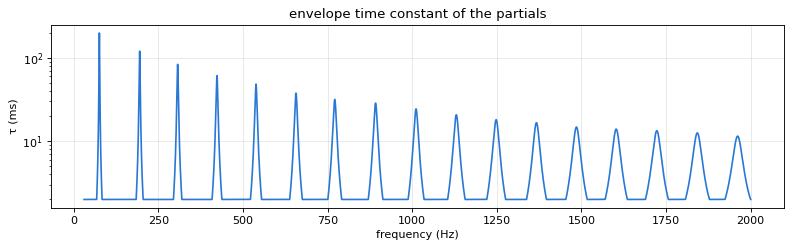

In [6]:
from didgelab.synth.bore import chain_matrix

syn = Synthesizer(bore, params)
f = np.arange(30, 2000, 0.05)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(f, 1000 * syn.envelope_time_constant(f))
r0 = bore.resonances[0]
ff = np.arange(r0.freq - 6, r0.freq + 6, 0.002)
A, B, C, D, Zr = chain_matrix(bore.geo, ff, bore.constants)
h = np.abs(1 / (C * Zr + D))
above = ff[h > h.max() / np.sqrt(2)]
bw = above[-1] - above[0]
print(f"drone: bandwidth {bw:.2f} Hz, 1/(pi B) = {1000 / (np.pi * bw):.0f} ms, "
      f"synthesizer tau = {1000 * syn.envelope_time_constant(ff[np.argmax(h)]):.0f} ms")
ax.set(xlabel="frequency (Hz)", ylabel="τ (ms)", yscale="log", title="envelope time constant of the partials")
plt.tight_layout(); plt.show()

### 3.5 A drone and a toot

A short score in the score language of `techniques.py`: three beats of drone, a toot (`*too`) on the
second resonance, and the drone again. `synthesize` builds the `Bore`, turns the score into control signals
and renders them. The toot is played 34 cents below the second resonance (`ModelParams.toot_cents`).

In [7]:
score = "tempo = 100\ndoo:3 *too:1.5 doo:1.5"
t = time.time()
y, fs = synthesize(geo, score, fs=16000)
print(f"rendered {len(y) / fs:.1f} s in {time.time() - t:.1f} s")
display(Audio(y, rate=fs))

rendered 4.0 s in 0.7 s


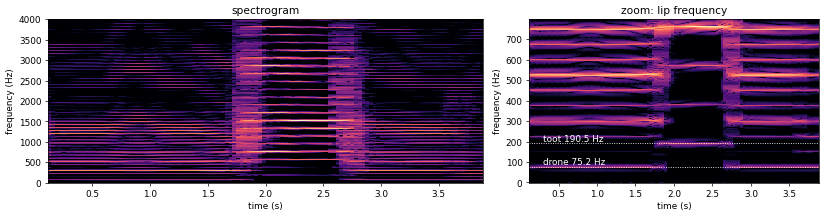

In [8]:
fr, tt, S = spectrogram(y, fs, nperseg=4096, noverlap=3584)
S = 10 * np.log10(S + 1e-20)
toot = bore.toot(1) * 2 ** (params.toot_cents / 1200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.5), dpi=64, gridspec_kw={"width_ratios": [3, 2]})
for a, fmax in [(a1, 4000), (a2, 800)]:
    k = fr <= fmax
    a.pcolormesh(tt, fr[k], S[k], vmin=S.max() - 60, vmax=S.max(), cmap="magma", shading="auto")
    a.grid(False)
    a.set(xlabel="time (s)", ylabel="frequency (Hz)")
a1.set_title("spectrogram")
a2.set_title("zoom: lip frequency")
a2.axhline(bore.drone, color="w", ls=":", lw=1); a2.text(0.3, bore.drone + 12, f"drone {bore.drone:.1f} Hz", color="w")
a2.axhline(toot, color="w", ls=":", lw=1); a2.text(0.3, toot + 12, f"toot {toot:.1f} Hz", color="w")
plt.tight_layout(); plt.show()

The drone has a dense row of harmonics. During the toot the lips play at the second resonance, so the
harmonics are wider apart.

### 3.6 A song

Songs are `.didge` text files with a rhythm lane (and an optional tongue lane), see
[song_format.md](../song_format.md). `render_song_loop` renders one pass of a song from `SONGS` as a
seamless loop on any geometry.

In [9]:
print(sorted(SONGS))
print()
print(SONGS["dong-tiki-ritititi"].read_text())

['dong-ti', 'dong-tiki-ritititi', 'drone-back-to-front', 'groove-demo', 'tiki-du']

# Rhythmic demo: "dong-tiki dong-tiki dong tiki ritititi"
# Beats 1 and 2: dong (eighth) + ti ki (sixteenths); beat 3: dong, tiki;
# beat 4: ri ti ti ti (sixteenths, "r" = a quick tongue flap).
title:      Dong-tiki ritititi
instrument: Arusha
tempo:      92
meter:      4/4

[rhythm]
| !dong-tiki dong-tiki dong:1/8 tiki:1/8 ritititi |



2.61 s (one bar of 4/4 at 92 bpm)


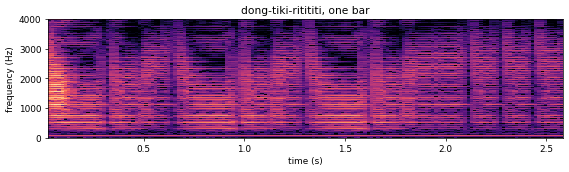

In [10]:
y, fs = render_song_loop(geo, "dong-tiki-ritititi", temperature=28, tempo=92, fs=16000)
print(f"{len(y) / fs:.2f} s (one bar of 4/4 at 92 bpm)")
display(Audio(y, rate=fs))

fr, tt, S = spectrogram(y, fs, nperseg=1024, noverlap=768)
S = 10 * np.log10(S + 1e-20)
k = fr <= 4000
fig, ax = plt.subplots(figsize=(9, 2.8), dpi=64)
ax.pcolormesh(tt, fr[k], S[k], vmin=S.max() - 60, vmax=S.max(), cmap="magma", shading="auto")
ax.grid(False)
ax.set(xlabel="time (s)", ylabel="frequency (Hz)", title="dong-tiki-ritititi, one bar")
plt.tight_layout(); plt.show()

The bright band moves with the vowels: around 1 kHz on "dong" (tongue back), 2–3 kHz on "ti" (tongue
front). The short dark vertical stripes are the tongue closures of the consonants.

### 3.7 The bell

The same 1.5 m tube as a cylinder (32 mm) and with a large bell that opens to 100 mm over the last 40 cm. A
wide bell radiates more sound at high frequencies, so less is reflected back into the tube: the higher
impedance peaks become **lower and broader** (here from 6–10 to 4–9 MPa s/m³ and from Q 64–98 to 57–71
above 300 Hz), and $|H|$ at those peaks drops as well. The bell also shortens the acoustic length, so all
resonances move up (here the drone from 57 to 66 Hz), and the higher toots move away from the 5, 7, 9 …
times the drone of the cylinder.

cylinder       57 Hz (23.8 MPa, Q 29)   173 Hz (13.5 MPa, Q 58)   288 Hz (10.2 MPa, Q 64)   404 Hz ( 8.5 MPa, Q 81)   520 Hz ( 7.3 MPa, Q 94)   635 Hz ( 6.4 MPa, Q 98)
100 mm bell    66 Hz (26.5 MPa, Q 33)   198 Hz (14.3 MPa, Q 57)   319 Hz ( 8.6 MPa, Q 71)   420 Hz ( 4.6 MPa, Q 60)   523 Hz ( 4.1 MPa, Q 58)   637 Hz ( 3.6 MPa, Q 61)


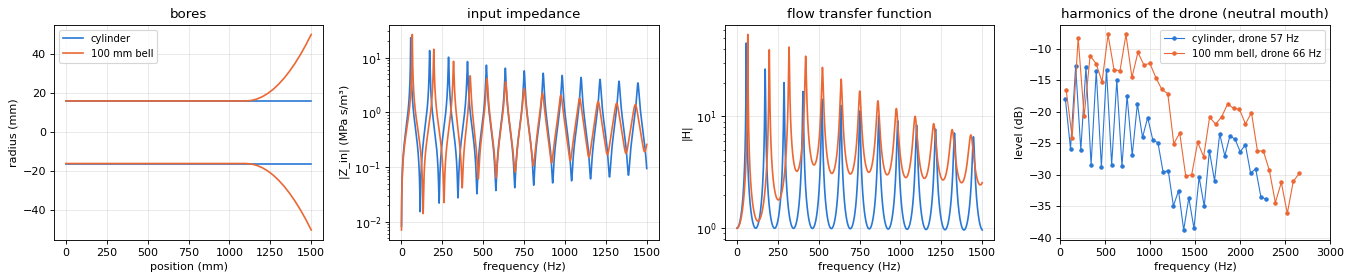

In [11]:
def with_bell(bell_d, L=1500, bell_len=400, d0=32):
    x = np.linspace(0, L - bell_len, 6)
    g = [[float(a), float(d0)] for a in x]
    xb = np.linspace(L - bell_len, L, 13)[1:]
    return g + [[float(a), float(d0 + (bell_d - d0) * ((a - L + bell_len) / bell_len) ** 2)] for a in xb]

bores = {"cylinder": Bore(with_bell(32), constants=constants),
         "100 mm bell": Bore(with_bell(100), constants=constants)}
for name, b in bores.items():
    print(f"{name:12s}", "  ".join(f"{r.freq:4.0f} Hz ({r.impedance / 1e6:4.1f} MPa, Q {r.q:2.0f})"
                                   for r in b.resonances[:6]))

fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for k, (name, b) in enumerate(bores.items()):
    plot_bore(axs[0], b.geo.geo, label=name, color=f"C{k}")
    m = b.freqs <= 1500
    axs[1].plot(b.freqs[m], np.abs(b.Zin[m]) / 1e6, color=f"C{k}", label=name)
    axs[2].plot(b.freqs[m], np.abs(b.H[m]), color=f"C{k}", label=name)
    nh = np.arange(1, 41)
    lv = db(harmonic_spectrum(b, b.drone, VOWELS["neutral"], params, n_harm=40))
    axs[3].plot(nh * b.drone, lv, "o-", ms=3, lw=1, color=f"C{k}", label=f"{name}, drone {b.drone:.0f} Hz")
axs[0].set_title("bores"); axs[0].legend(fontsize=9)
axs[1].set(xlabel="frequency (Hz)", ylabel="|Z_in| (MPa s/m³)", yscale="log", title="input impedance")
axs[2].set(xlabel="frequency (Hz)", ylabel="|H|", yscale="log", title="flow transfer function")
axs[3].set(xlabel="frequency (Hz)", ylabel="level (dB)", xlim=(0, 3000), title="harmonics of the drone (neutral mouth)")
axs[3].legend(fontsize=9)
plt.tight_layout(); plt.show()

The cylinder (closed at the lips, open at the bell) has resonances near 1, 3, 5, 7 times the drone, so its
odd harmonics are strong and its even harmonics weak. With the bell the resonances above 300 Hz are
weaker and broader.

**Limits.** The model plays the drone exactly on the first resonance and toots 34 cents below the higher
ones; the lips do not oscillate by themselves. The bell is a plane-wave transmission line with the radiation
impedance of an unflanged pipe, which is less accurate for strongly flaring bells. See section 10 of
[synthesizer.md](../synthesizer.md).